# Лабораторная 5. Детекция голов: обучение YOLO, метрики, разбор ошибок, выбор порога

Задание целиком: `labs/lab05/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 8): датасет в формате YOLO, дообучение детектора, mAP на val, кривые обучения, примеры предсказаний;
- **Часть 2** (после лекции 9): разбор ошибок по категориям, выбор порога уверенности под требование задачи, один прогон на test.

Как работать:
1. В первой ячейке впишите свой номер варианта, в разделе 1.1 путь к своему `split.csv` из лабы 3.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Нужен GPU: в Kaggle Settings → Accelerator → GPU T4 и Settings → Internet → On; в Colab Среда выполнения → Сменить среду → T4 GPU.

## 0. Установка и загрузка данных

Та же ячейка, что в лабах 1–4. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 12
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab05/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: /home/anton/cv-2026-kucher/data
Вариант 12 уже на месте: /home/anton/cv-2026-kucher/data/variant_12


данные варианта: /home/anton/cv-2026-kucher/data/variant_12
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
# ultralytics: библиотека YOLO. В Kaggle и Colab её нужно поставить, это занимает около минуты
try:
    import ultralytics
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics>=8.3.0"])
    import ultralytics
from ultralytics import YOLO

import json
import multiprocessing
if multiprocessing.get_start_method(allow_none=True) != "fork":
    try:
        multiprocessing.set_start_method("fork", force=True)
    except RuntimeError:
        pass

import random
import shutil
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

labels = pd.read_csv(DATA_DIR / "labels.csv")
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
CLASSES = list(variant_info["breeds"])          # индекс в списке = class_id из labels.csv
K = len(CLASSES)
DEVICE = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(len(labels), "фото | классы:", dict(enumerate(CLASSES)))
print("устройство:", DEVICE, "| ultralytics", ultralytics.__version__, "| torch", torch.__version__)
if DEVICE == "cpu":
    print("ВНИМАНИЕ: GPU не найден, обучение пойдёт очень долго. В Kaggle и Colab включите GPU T4")

786 фото | классы: {0: 'Bombay', 1: 'Egyptian_Mau', 2: 'american_pit_bull_terrier', 3: 'staffordshire_bull_terrier'}
устройство: 0 | ultralytics 8.4.218 | torch 2.15.0+cu132


### Общие функции

Готовый код, менять не нужно.

- `read_boxes(filename)` читает рамки голов из Pascal VOC XML: список `[xmin, ymin, xmax, ymax]` в пикселях, отсчёт от 0. Если XML нет, возвращает `None`.
- `iou(a, b)` — IoU двух рамок `[x1, y1, x2, y2]`: площадь пересечения, делённая на площадь объединения.
- `draw(rgb, boxes, color, texts)` рисует рамки с подписями, `show_grid` выводит картинки сеткой и сохраняет PNG.

In [3]:
def read_boxes(filename):
    path = XML_DIR / (Path(filename).stem + ".xml")
    if not path.exists():
        return None
    root = ET.parse(path).getroot()
    out = []
    for obj in root.findall("object"):
        bb = obj.find("bndbox")
        x1, y1, x2, y2 = [float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
        out.append([x1 - 1, y1 - 1, x2, y2])          # VOC считает пиксели с 1
    return out


def iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def load_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def draw(rgb, boxes, color, texts=None):
    out = np.ascontiguousarray(rgb.copy())
    th = max(2, round(max(rgb.shape[:2]) / 250))
    for i, b in enumerate(boxes):
        x1, y1, x2, y2 = [int(round(v)) for v in b[:4]]
        cv2.rectangle(out, (x1, y1), (x2, y2), color, th)
        if texts:
            cv2.putText(out, texts[i], (x1 + 3, max(y1 - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, th / 3, color, max(1, th // 2))
    return out


def show_grid(images, titles=None, ncols=4, path=None, size=3.2):
    if len(images) == 0:
        print("показывать нечего: список картинок пуст")
        return
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=8)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


def cname(c):
    """Имя класса; у модели COCO без дообучения классов больше, чем пород."""
    c = int(c)
    return CLASSES[c][:10] if c < K else f"coco {c}"


assert abs(iou([0, 0, 10, 10], [5, 0, 15, 10]) - 1 / 3) < 1e-9

# Часть 1. Датасет YOLO и обучение детектора

Делается после лекции 8. Детектор учится находить голову животного и называть породу: классов столько же, сколько пород в варианте. Берём YOLO11n, обученную на COCO, и дообучаем на ваших фото. Результат части: кривые обучения, mAP на val и примеры предсказаний.

## 1.1 Разбиение из лабы 3

Как в лабе 4: впишите в `SPLIT_CSV` путь к своему `split.csv` (локально `"../lab03/results/split.csv"`) или raw-ссылку на него в вашем репозитории на GitHub (в Kaggle и Colab).

In [4]:
# Локально берём из lab03/results/split.csv, в облаке — по raw-ссылке репозитория
SPLIT_CSV = "../lab03/results/split.csv" if Path("../lab03/results/split.csv").exists() else "https://raw.githubusercontent.com/kucheranton200/cv-2026-kucher/main/lab03/results/split.csv"


In [5]:
assert SPLIT_CSV, "Впишите в SPLIT_CSV путь или ссылку на свой split.csv из лабы 3"
split = pd.read_csv(SPLIT_CSV)
df = labels.merge(split[["filename", "group", "split"]], on="filename", how="left")
missing = int(df["split"].isna().sum())
assert missing == 0, f"{missing} фото варианта нет в split.csv: это split.csv другого варианта?"
assert int((df.groupby("group")["split"].nunique() > 1).sum()) == 0, "есть разорванные группы: проверьте разбиение в лабе 3"
df["boxes"] = df["filename"].map(read_boxes)
df["has_box"] = df["boxes"].notna()
print(pd.crosstab(df["split"], df["has_box"]).reindex(["train", "val", "test"]).rename(columns={True: "с рамкой", False: "без рамки"}).to_string())

has_box  без рамки  с рамкой
split                       
train          286       275
val             57        55
test            51        62


## 1.2 Датасет в формате YOLO

Готовый код. Ultralytics ждёт папку с подпапками `images/train|val|test` и `labels/train|val|test` и файл `data.yaml` с путями и именами классов. Строка разметки — тот же формат, что вы делали в лабе 3: `class cx cy w h` в долях кадра.

В датасет берём **только фото с XML**. У фото без XML голова на снимке есть, просто её никто не обвёл. Если положить такое фото в обучение с пустой разметкой, детектор будет учиться, что голова — это фон. Неразмеченное — не значит «объекта нет».

In [6]:
YOLO_DIR = Path("yolo_data").resolve()
shutil.rmtree(YOLO_DIR, ignore_errors=True)
for part in ("train", "val", "test"):
    (YOLO_DIR / "images" / part).mkdir(parents=True)
    (YOLO_DIR / "labels" / part).mkdir(parents=True)

data = df[df["has_box"]].reset_index(drop=True)
for r in data.itertuples():
    h, w = cv2.imread(str(IMG_DIR / r.filename)).shape[:2]
    lines = [f"{r.class_id} {(b[0] + b[2]) / 2 / w:.6f} {(b[1] + b[3]) / 2 / h:.6f} {(b[2] - b[0]) / w:.6f} {(b[3] - b[1]) / h:.6f}"
             for b in r.boxes]
    shutil.copy(IMG_DIR / r.filename, YOLO_DIR / "images" / r.split / r.filename)
    (YOLO_DIR / "labels" / r.split / (Path(r.filename).stem + ".txt")).write_text("\n".join(lines) + "\n")

DATA_YAML = YOLO_DIR / "data.yaml"
DATA_YAML.write_text(json.dumps({"path": str(YOLO_DIR), "train": "images/train", "val": "images/val",
                                 "test": "images/test", "names": dict(enumerate(CLASSES))}, ensure_ascii=False))
print(data["split"].value_counts().reindex(["train", "val", "test"]).to_dict(), "фото с рамкой |",
      int(data["boxes"].map(len).sum()), "рамок")

{'train': 275, 'val': 55, 'test': 62} фото с рамкой | 392 рамок


## 1.3 Обучение

Допишите вызов обучения. Модель создаётся из весов, обученных на COCO: `YOLO("yolo11n.pt")`, ultralytics скачает их сам. Дальше `model.train(...)` с параметрами:

| Параметр | Значение | Зачем |
|---|---|---|
| `data` | `str(DATA_YAML)` | где датасет |
| `epochs` | `EPOCHS` | число эпох |
| `imgsz` | `IMGSZ` | сторона квадрата, к которой приводится фото |
| `batch` | `16` | фото в батче |
| `device` | `DEVICE` | GPU или CPU |
| `seed`, `deterministic` | `SEED`, `True` | чтобы перезапуск давал те же числа |
| `project`, `name`, `exist_ok` | `str(RUNS)`, `"train"`, `True` | куда сложить веса и логи |
| `plots` | `False` | свои графики нарисуем сами |

Лучшие по val веса ultralytics сохранит в `runs/train/weights/best.pt`, историю по эпохам — в `runs/train/results.csv`. Готовая ячейка ниже загрузит лучшие веса.

In [7]:
MODEL = "yolo11n.pt"   # можно попробовать "yolo26n.pt" — следующее поколение, без NMS
EPOCHS, IMGSZ = 40, 640
RUNS = Path("runs").resolve()

model = YOLO(MODEL)
model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=16, device=DEVICE,
            seed=SEED, deterministic=True, project=str(RUNS), name="train", exist_ok=True, plots=False)


Ultralytics 8.4.218 🚀 Python-3.14.4 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4070, 11872MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/anton/cv-2026-kucher/lab05/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, p

Overriding model.yaml nc=80 with nc=4



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (537 outputs left out)

american_pit_bull_terrier         11         11      0.915      0.818       0.89      0.755


staffordshire_bull_terrier         17         17      0.849          1      0.944      0.842


Speed: 0.7ms preprocess, 2.4ms inference, 0.0ms loss, 0.3ms postprocess per image


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783af851cad0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [8]:
BEST = RUNS / "train" / "weights" / "best.pt"
if BEST.exists():
    model = YOLO(BEST)
    hist = pd.read_csv(RUNS / "train" / "results.csv")
    hist.columns = [c.strip() for c in hist.columns]
    hist.to_csv(RESULTS / "train_results.csv", index=False)
    print("лучшие веса:", BEST, "| эпох:", len(hist))
else:
    # часть 1 ещё не сделана: берём модель COCO без дообучения, чтобы ячейки ниже не падали
    model = YOLO(MODEL)
    hist = None
    print("ВНИМАНИЕ: обучения не было, ниже работает модель COCO без дообучения")

лучшие веса: /home/anton/cv-2026-kucher/lab05/runs/train/weights/best.pt | эпох: 40


## 1.4 Кривые обучения и mAP на val

Готовая ячейка рисует потери рамки (`box_loss`) и класса (`cls_loss`) на train и val и mAP@50 и mAP@50–95 на val по эпохам и сохраняет `curves.png`. Потом считает метрики лучшей модели на val и сохраняет `metrics_val.json`: mAP@50, mAP@50–95, precision, recall и AP@50–95 по каждой породе. Test пока не трогаем.

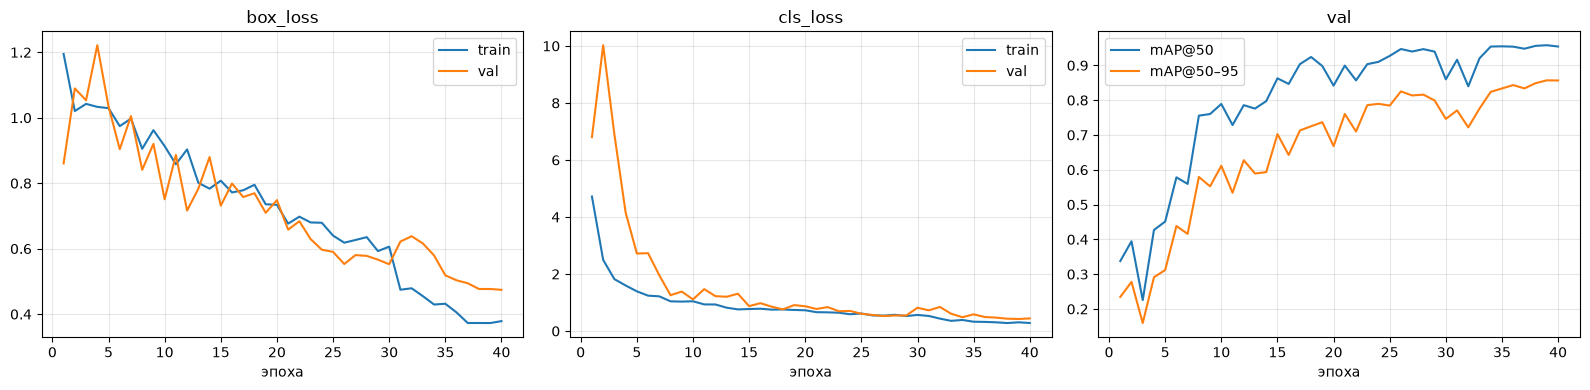

Ultralytics 8.4.218 🚀 Python-3.14.4 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4070, 11872MiB)


YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4668.9±3114.5 MB/s, size: 67.3 KB)


val: Scanning /home/anton/cv-2026-kucher/lab05/yolo_data/labels/val.cache... 55 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 38.4Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 1.1it/s 0.3s<2.6s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 10.4it/s 0.4s

                   all         55         55      0.933      0.954      0.956      0.855


Speed: 0.8ms preprocess, 1.3ms inference, 0.0ms loss, 0.3ms postprocess per image


variant                                                             12
model                                                       yolo11n.pt
epochs                                                              40
imgsz                                                              640
mAP50                                                           0.9564
mAP50_95                                                        0.8553
precision                                                       0.9331
recall                                                           0.954
AP50_95_per_class    {'Bombay': 0.9345, 'Egyptian_Mau': 0.8996, 'am...
dtype: object

In [9]:
if hist is not None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, key in zip(axes[:2], ["box_loss", "cls_loss"]):
        ax.plot(hist["epoch"], hist[f"train/{key}"], label="train")
        ax.plot(hist["epoch"], hist[f"val/{key}"], label="val")
        ax.set_title(key); ax.set_xlabel("эпоха"); ax.legend(); ax.grid(alpha=0.3)
    axes[2].plot(hist["epoch"], hist["metrics/mAP50(B)"], label="mAP@50")
    axes[2].plot(hist["epoch"], hist["metrics/mAP50-95(B)"], label="mAP@50–95")
    axes[2].set_title("val"); axes[2].set_xlabel("эпоха"); axes[2].legend(); axes[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS / "curves.png", dpi=100)
    plt.show()

m = model.val(data=str(DATA_YAML), split="val", imgsz=IMGSZ, batch=16, device=DEVICE, plots=False, verbose=False)
metrics_val = {"variant": VARIANT, "model": MODEL, "epochs": EPOCHS, "imgsz": IMGSZ,
               "mAP50": round(float(m.box.map50), 4), "mAP50_95": round(float(m.box.map), 4),
               "precision": round(float(m.box.mp), 4), "recall": round(float(m.box.mr), 4),
               "AP50_95_per_class": {CLASSES[int(c)]: round(float(a), 4) for c, a in zip(m.box.ap_class_index, m.box.maps[m.box.ap_class_index])}}
(RESULTS / "metrics_val.json").write_text(json.dumps(metrics_val, ensure_ascii=False, indent=1), encoding="utf-8")
pd.Series(metrics_val)

## 1.5 Примеры предсказаний

Готовая ячейка рисует 8 фото val: зелёным правильные рамки, жёлтым предсказания с уверенностью выше 0,25 (порог ultralytics по умолчанию), и сохраняет `predictions.png`. Посмотрите, где рамки точные, а где нет.

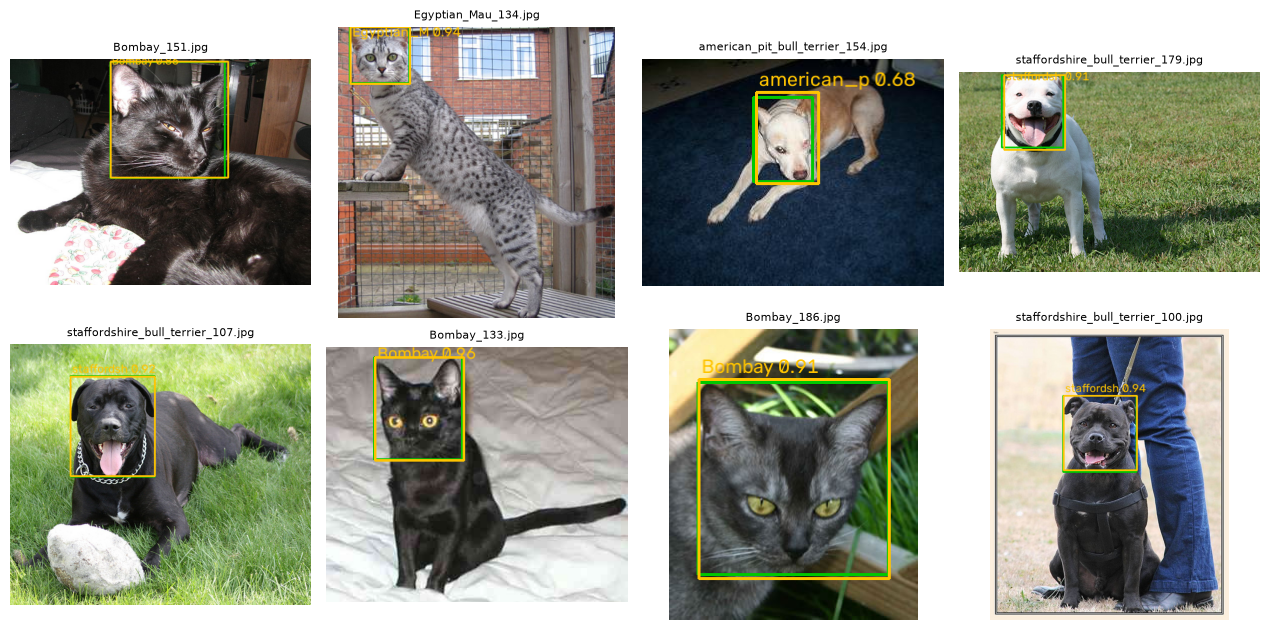

In [10]:
val_files = sorted(data.loc[data["split"] == "val", "filename"])
show = random.Random(SEED).sample(val_files, min(8, len(val_files)))
panels, titles = [], []
for fn, r in zip(show, model.predict([str(IMG_DIR / f) for f in show], conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)):
    rgb = load_rgb(IMG_DIR / fn)
    gt = data.loc[data["filename"] == fn, "boxes"].iloc[0]
    pb = r.boxes.xyxy.cpu().numpy().tolist()
    txt = [f"{cname(c)} {s:.2f}" for c, s in zip(r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy())]
    panels.append(draw(draw(rgb, gt, (0, 200, 0)), pb, (255, 196, 0), txt))
    titles.append(fn)
show_grid(panels, titles, ncols=4, path=RESULTS / "predictions.png")

# Часть 2. Ошибки детектора и выбор порога

Делается после лекции 9. Сначала собираем все предсказания модели на val с очень низким порогом, чтобы дальше выбирать порог самим. Затем раскладываем ошибки по категориям, выбираем порог уверенности под требование задачи и один раз проверяем всё на test.

## 2.1 Все предсказания

Готовый код. Модель предсказывает на val и test с порогом `conf=0.001`, то есть возвращает почти все свои кандидаты вместе с уверенностью. Порог применим потом сами. Таблица `PRED`: фото, выборка, класс, уверенность, рамка. Таблица `GT`: правильные рамки.

In [11]:
def predict_table(part):
    files = sorted(data.loc[data["split"] == part, "filename"])
    rows = []
    for fn, r in zip(files, model.predict([str(IMG_DIR / f) for f in files], conf=0.001, imgsz=IMGSZ,
                                          device=DEVICE, verbose=False, stream=True)):
        for b, c, s in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()):
            rows.append({"filename": fn, "split": part, "cls": int(c), "conf": float(s), "box": b.tolist()})
    return pd.DataFrame(rows, columns=["filename", "split", "cls", "conf", "box"])


PRED = pd.concat([predict_table("val"), predict_table("test")], ignore_index=True)
GT = pd.DataFrame([{"filename": r.filename, "split": r.split, "cls": r.class_id, "box": b}
                   for r in data[data["split"].isin(["val", "test"])].itertuples() for b in r.boxes])
print("предсказаний:", PRED.groupby("split").size().to_dict(), "| правильных рамок:", GT.groupby("split").size().to_dict())

предсказаний: {'test': 158, 'val': 158} | правильных рамок: {'test': 62, 'val': 55}


## 2.2 Категории ошибок

Допишите `categorize(preds, gts)` для одного фото. На входе предсказания этого фото, уже отфильтрованные по порогу и отсортированные по убыванию уверенности, и правильные рамки. Функция возвращает список категорий: по одной на каждое предсказание и по одной на каждую ненайденную правильную рамку.

Правила, по порядку для каждого предсказания:

| Категория | Условие |
|---|---|
| `верно` | есть ещё не занятая правильная рамка того же класса с IoU ≥ 0,5. Берём рамку с наибольшим IoU и помечаем занятой |
| `дубль` | рамка того же класса с IoU ≥ 0,5 есть, но уже занята более уверенным предсказанием |
| `класс` | IoU ≥ 0,5 с правильной рамкой другого класса: голову нашли, породу перепутали |
| `локализация` | наибольший IoU с правильной рамкой того же класса от 0,1 до 0,5: голову нашли, но рамка неточная |
| `фон` | всё остальное: рамка там, где головы нет |

После всех предсказаний каждая правильная рамка, которая не стала `верно`, добавляет категорию `пропуск`.

Это упрощённая версия разбора ошибок из библиотеки TIDE (лекция 9). Готовые ячейки ниже проверят функцию на маленьком примере и посчитают категории на val при пороге 0,25.

In [12]:
def categorize(preds, gts):
    """preds: список (cls, conf, box), по убыванию conf; gts: список (cls, box). Возвращает список категорий."""
    taken = [False] * len(gts)
    cats = []
    for p_cls, p_conf, p_box in preds:
        ious = [iou(p_box, g_box) for _, g_box in gts]
        # 1. верно: свободная рамка того же класса с наибольшим IoU >= 0.5
        same_available = [(ious[j], j) for j, (g_cls, _) in enumerate(gts) if g_cls == p_cls and not taken[j] and ious[j] >= 0.5]
        if same_available:
            same_available.sort(key=lambda x: x[0], reverse=True)
            best_iou, best_j = same_available[0]
            taken[best_j] = True
            cats.append("верно")
            continue

        # 2. дубль: рамка того же класса с IoU >= 0.5 уже занята
        same_taken = [j for j, (g_cls, _) in enumerate(gts) if g_cls == p_cls and taken[j] and ious[j] >= 0.5]
        if same_taken:
            cats.append("дубль")
            continue

        # 3. класс: IoU >= 0.5 с рамкой другого класса (голову нашли, породу перепутали)
        diff_class = [j for j, (g_cls, _) in enumerate(gts) if g_cls != p_cls and ious[j] >= 0.5]
        if diff_class:
            cats.append("класс")
            continue

        # 4. локализация: наибольший IoU с рамкой того же класса от 0.1 до 0.5
        same_loc = [ious[j] for j, (g_cls, _) in enumerate(gts) if g_cls == p_cls and 0.1 <= ious[j] < 0.5]
        if same_loc:
            cats.append("локализация")
            continue

        # 5. фон: всё остальное
        cats.append("фон")

    # Все ненайденные рамки gt отмечаются как пропуск
    for j, is_taken in enumerate(taken):
        if not is_taken:
            cats.append("пропуск")

    return cats


In [13]:
# проверка на игрушечном примере: одна правильная рамка класса 0
_gt = [(0, [0, 0, 100, 100])]
_tests = [
    ([(0, 0.9, [0, 0, 100, 100])], ["верно"]),
    ([(0, 0.9, [0, 0, 100, 100]), (0, 0.8, [5, 5, 100, 100])], ["верно", "дубль"]),
    ([(1, 0.9, [0, 0, 100, 100])], ["класс", "пропуск"]),
    ([(0, 0.9, [50, 50, 150, 150])], ["локализация", "пропуск"]),
    ([(0, 0.9, [300, 300, 400, 400])], ["фон", "пропуск"]),
    ([], ["пропуск"]),
]
_ok = sum(categorize(p, _gt) == want for p, want in _tests)
print(f"categorize: {_ok} из {len(_tests)} проверок прошли" + ("" if _ok == len(_tests) else " — допишите функцию"))

CATS = ["верно", "класс", "локализация", "дубль", "фон", "пропуск"]


def error_table(part, conf):
    rows = []
    for fn in sorted(data.loc[data["split"] == part, "filename"]):
        p = PRED[(PRED["filename"] == fn) & (PRED["conf"] >= conf)].sort_values("conf", ascending=False)
        g = GT[GT["filename"] == fn]
        cats = categorize(list(zip(p["cls"], p["conf"], p["box"])), list(zip(g["cls"], g["box"])))
        rows += [{"filename": fn, "category": c} for c in cats]
    return pd.DataFrame(rows, columns=["filename", "category"])


err = error_table("val", 0.25)
counts = err["category"].value_counts().reindex(CATS, fill_value=0)
counts.rename("val, conf 0.25").to_frame().T.to_csv(RESULTS / "errors.csv")
counts.to_frame("val, порог 0,25").T

categorize: 6 из 6 проверок прошли


category,верно,класс,локализация,дубль,фон,пропуск
"val, порог 0,25",53,4,0,0,1,2


## 2.3 Ошибки глазами

Готовая ячейка показывает по 2 фото на каждую категорию ошибок (если такие есть) с правильными рамками зелёным и предсказаниями жёлтым и сохраняет `errors.png`. Посмотрите на них: в отчёте нужно объяснить, откуда берётся самая частая категория ошибок на вашем варианте.

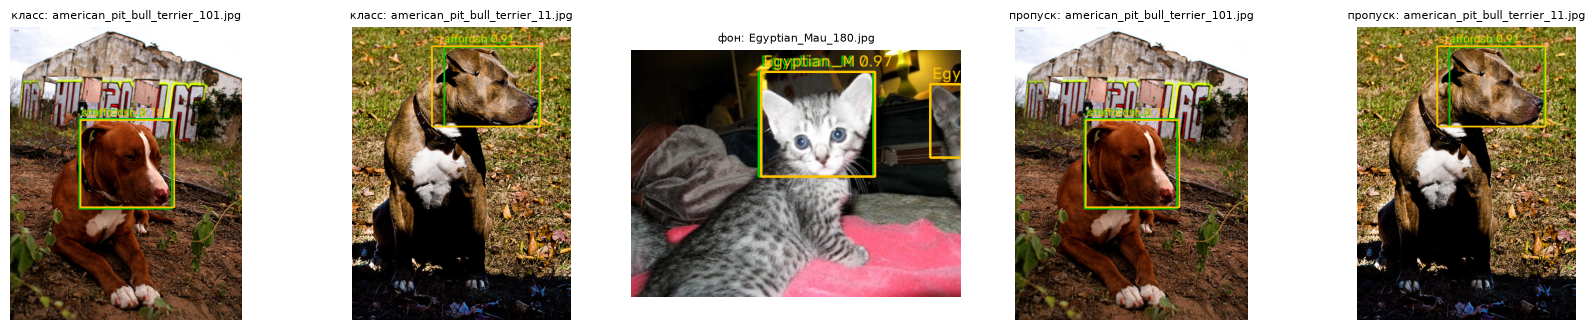

In [14]:
panels, titles = [], []
for cat in ["класс", "локализация", "дубль", "фон", "пропуск"]:
    for fn in err.loc[err["category"] == cat, "filename"].drop_duplicates().head(2):
        rgb = load_rgb(IMG_DIR / fn)
        p = PRED[(PRED["filename"] == fn) & (PRED["conf"] >= 0.25)]
        g = GT[GT["filename"] == fn]
        img = draw(rgb, list(g["box"]), (0, 200, 0), [cname(c) for c in g["cls"]])
        img = draw(img, list(p["box"]), (255, 196, 0), [f"{cname(c)} {s:.2f}" for c, s in zip(p["cls"], p["conf"])])
        panels.append(img)
        titles.append(f"{cat}: {fn}")
show_grid(panels, titles, ncols=5, path=RESULTS / "errors.png", size=3.4)

## 2.4 Выбор порога

Готовая ячейка считает на val precision, recall и F1 при порогах уверенности от 0,05 до 0,95: верным считается предсказание категории `верно`, все рамки — правильные рамки val. Рисует кривые и сохраняет `threshold.png` и `threshold.csv`.

Затем ваша часть. Придумайте, для чего мог бы работать ваш детектор голов, и сформулируйте требование одной фразой: что дороже, пропуск или ложное срабатывание, и какое число нужно. Например: «детектор для фотоловушки в приюте: пропустить животное хуже, чем показать лишний кадр; recall не ниже 0,95, при этом precision как можно выше». Впишите требование в `REQUIREMENT` и выберите порог `CONF`, который ему удовлетворяет, по таблице `thr`. Если требование недостижимо, напишите это в отчёте и выберите ближайший порог.

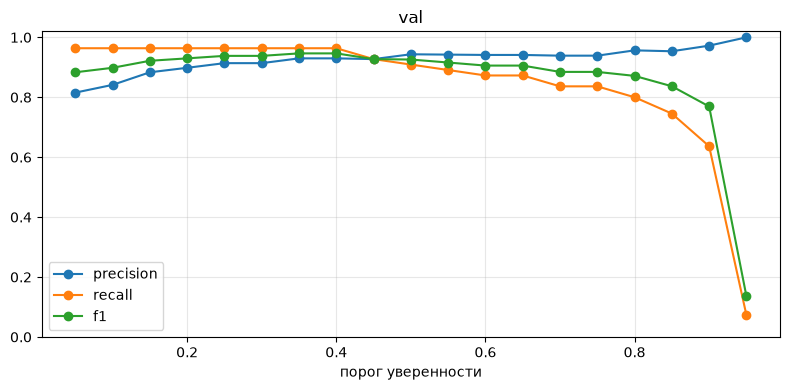

,conf,tp,predicted,precision,recall,f1
0,0.05,53,65,0.8154,0.9636,0.8833
1,0.10,53,63,0.8413,0.9636,0.8983
2,0.15,53,60,0.8833,0.9636,0.9217
3,0.20,53,59,0.8983,0.9636,0.9298
4,0.25,53,58,0.9138,0.9636,0.9381
5,0.30,53,58,0.9138,0.9636,0.9381
6,0.35,53,57,0.9298,0.9636,0.9464
7,0.40,53,57,0.9298,0.9636,0.9464
8,0.45,51,55,0.9273,0.9273,0.9273
9,0.50,50,53,0.9434,0.9091,0.9259


In [15]:
def pr_at(part, conf):
    e = error_table(part, conf)
    tp = int((e["category"] == "верно").sum())
    n_pred = int((e["category"] != "пропуск").sum())
    n_gt = int((GT["split"] == part).sum())
    p = tp / n_pred if n_pred else 1.0
    r = tp / n_gt
    return {"conf": conf, "tp": tp, "predicted": n_pred, "precision": round(p, 4), "recall": round(r, 4),
            "f1": round(2 * p * r / (p + r), 4) if p + r else 0.0}


thr = pd.DataFrame([pr_at("val", c) for c in np.round(np.arange(0.05, 0.96, 0.05), 2)])
thr.to_csv(RESULTS / "threshold.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
for k in ["precision", "recall", "f1"]:
    ax.plot(thr["conf"], thr[k], "o-", label=k)
ax.set_xlabel("порог уверенности"); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(); ax.set_title("val")
plt.tight_layout()
plt.savefig(RESULTS / "threshold.png", dpi=100)
plt.show()
thr

In [16]:
# Требование к детектору и порог, выбранный по таблице thr на val:
REQUIREMENT = "детектор для автоматической кормушки: ложные срабатывания на фон или чужую породу нежелательны; precision не ниже 0.95 при recall не ниже 0.90"
CONF = 0.70


## 2.5 Тест

Test открываем один раз, когда порог уже выбран. Готовая ячейка считает на test mAP@50 и mAP@50–95 (они от порога не зависят), precision, recall и F1 при вашем `CONF` и категории ошибок при этом пороге и сохраняет `test_metrics.csv`. Сравните с val: если recall на test заметно ниже требования, напишите в отчёте, почему так могло получиться.

In [17]:
mt = model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=16, device=DEVICE, plots=False, verbose=False)
at_val, at_test = pr_at("val", CONF), pr_at("test", CONF)
cats_test = error_table("test", CONF)["category"].value_counts().reindex(CATS, fill_value=0)
test_metrics = pd.DataFrame([
    {"split": "val", "mAP50": metrics_val["mAP50"], "mAP50_95": metrics_val["mAP50_95"], **at_val},
    {"split": "test", "mAP50": round(float(mt.box.map50), 4), "mAP50_95": round(float(mt.box.map), 4), **at_test,
     **{f"n_{c}": int(cats_test[c]) for c in CATS}},
])
test_metrics.insert(0, "requirement", REQUIREMENT)
test_metrics.to_csv(RESULTS / "test_metrics.csv", index=False)
test_metrics.drop(columns="requirement")

Ultralytics 8.4.218 🚀 Python-3.14.4 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4070, 11872MiB)


YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3409.0±2620.1 MB/s, size: 66.6 KB)


val: Scanning /home/anton/cv-2026-kucher/lab05/yolo_data/labels/test... 62 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 62/62 4.2Kit/s 0.0s

val: New cache created: /home/anton/cv-2026-kucher/lab05/yolo_data/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 1.1it/s 0.3s<2.7s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 9.9it/s 0.4s

                   all         62         62       0.97      0.943       0.98      0.863


Speed: 0.9ms preprocess, 1.2ms inference, 0.0ms loss, 0.3ms postprocess per image


,split,mAP50,mAP50_95,conf,tp,predicted,precision,recall,f1,n_верно,n_класс,n_локализация,n_дубль,n_фон,n_пропуск
0,val,0.9564,0.8553,0.7,46,49,0.9388,0.8364,0.8846,NaN,NaN,NaN,NaN,NaN,NaN
1,test,0.9801,0.8630,0.7,57,59,0.9661,0.9194,0.9421,57.0,2.0,0.0,0.0,0.0,5.0


## Выгрузка

Ячейка ниже проверяет, что все 9 результатов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab05/`.

Переименуйте скачанный ноутбук в `solution.ipynb`. Папки `runs/` и `yolo_data/` и веса `*.pt` в репозиторий не кладём.

In [18]:
print(f"вариант {VARIANT} | {MODEL}, {EPOCHS} эпох, imgsz {IMGSZ} | val mAP@50 {metrics_val['mAP50']:.3f}, "
      f"mAP@50–95 {metrics_val['mAP50_95']:.3f} | порог {CONF}")
print("test:", test_metrics.loc[test_metrics["split"] == "test", ["mAP50", "mAP50_95", "precision", "recall"]].to_dict("records")[0])
expected = {"train_results.csv", "curves.png", "metrics_val.json", "predictions.png", "errors.csv", "errors.png",
            "threshold.png", "threshold.csv", "test_metrics.csv"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 результатов на месте")

вариант 12 | yolo11n.pt, 40 эпох, imgsz 640 | val mAP@50 0.956, mAP@50–95 0.855 | порог 0.7
test: {'mAP50': 0.9801, 'mAP50_95': 0.863, 'precision': 0.9661, 'recall': 0.9194}
не хватает: ничего, все 9 результатов на месте


In [19]:
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)